# Experiment 2A: Can BO recover after missing basin B?

In Experiment 1, ordinary BO at $c=10$ made no later discoveries among the eight runs that had yet to beat A after 12 evaluations. We test whether changing how BO selects its remaining evaluations can help it find B and reach a precise solution within the same budget of 50 calls.

For each penalty and seed, we run ordinary Expected Improvement (EI) for 12 calls. If the best observed value is still at least 1, we try different methods from there onwards.

| Variant | Calls 13–40 | Calls 41–50 |
|---|---|---|
| Ordinary EI | EI with $\xi=0$ | EI with $\xi=0$ |
| Higher xi | EI with selected positive $\xi$ | EI with $\xi=0$ |
| Uniform probes | Ten uniform probes, with ordinary EI on other calls | EI with $\xi=0$ |
| Higher xi + probes | The same ten probes, with higher-$\xi$ EI on other calls | EI with $\xi=0$ |

The probes replace EI proposals at calls 13, 16, ..., 40. Both probe variants use the same uniform points within a seed. The GP receives every evaluated point and its objective value.

**Hypothesis.** Allocating some evaluations to global exploration will increase the chance of beating A among unresolved BO runs. A higher $\xi$ may achieve a similar effect through the acquisition function. We measure whether each intervention broadens coverage and whether additional discoveries carry over to the precision target.

We test all four variants on seeds 100-149 at $c=10$ and $c=30$, with the higher exploration value fixed at $\xi=0.5$.

## 1. Setup

The next cell imports libraries and executes the definitions from `methods.ipynb` and `configurations.ipynb`.
The current experiment attempts seeds 100-149 at both $c=10$ and $c=30$. Each continuation has a total budget of 50 evaluations, including the shared 12-call history before the variants diverge. The discovery target is strictly below 1, and the precision target is strictly below 0.01.

In [1]:
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from skopt import Optimizer
from skopt.space import Real
from skopt.utils import cook_estimator, normalize_dimensions
from threadpoolctl import threadpool_limits

# Supports starting Jupyter from either the repository root or code/.
code_dir = Path("code") if Path("code/configurations.ipynb").is_file() else Path(".")

for filename in ("methods.ipynb", "configurations.ipynb"):
    path = code_dir / filename
    notebook = json.loads(path.read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])
            exec(source)

# Experiment settings are defined in configurations.ipynb.
PENALTIES = EXPERIMENT_2A_SETTINGS["penalties"]
MAIN_SEEDS = EXPERIMENT_2A_SETTINGS["main_seeds"]
chosen_xi = EXPERIMENT_2A_SETTINGS["chosen_xi"]

FORK = EXPERIMENT_2A_SETTINGS["fork"]
EXPLORE_END = EXPERIMENT_2A_SETTINGS["explore_end"]
BUDGET = EXPERIMENT_2A_SETTINGS["budget"]
PROBE_CALLS = EXPERIMENT_2A_SETTINGS["probe_calls"]

DISCOVERY = EXPERIMENT_2A_SETTINGS["discovery"]
PRECISION = EXPERIMENT_2A_SETTINGS["precision"]

bounds = DOMAIN_BOUNDS
lower, upper = bounds.T
bo_params = METHOD_PARAMS["BO"]

## 2. Define the BO variants

The next cell defines the following:

- **`new_bo(seed)`**: the normalised two-dimensional space, Gaussian-process estimator, and EI optimiser
- **`shared_initial_trial(c, seed)`**: evaluates ordinary EI through call 12. 
- **`continue_bo(initial_trial, xi, probes)`**: copies the previous information from the initial shared call.

The coverage helpers use only calls 13-40:

| Measure | Definition and interpretation |
|---|---|
| `new_cells` | Number of newly visited 1-by-1 grid cells in the domain, excluding cells already visited by previous calculations; larger values indicate broader spatial coverage |
| `near_a` | Fraction of exploration-window points within distance 1 of A; larger values indicate more concentration around the inferior minimum |
| `closest_b` | Minimum distance to B from calls 13–40; smaller values indicate a closer approach to the better basin |

In [2]:
def new_bo(seed):
    rng = np.random.RandomState(seed)
    space = normalize_dimensions(
        [Real(float(lo), float(hi)) for lo, hi in bounds]
    )
    estimator = cook_estimator(
        "GP",
        space=space,
        noise=bo_params["noise"],
        random_state=rng.randint(0, np.iinfo(np.int32).max),
    )
    return Optimizer(
        space,
        base_estimator=estimator,
        n_initial_points=bo_params["n_initial_points"],
        acq_func="EI",
        acq_func_kwargs={"xi": 0.0},
        random_state=rng,
    )


def shared_initial_trial(c, seed):
    opt = new_bo(seed)
    recorder = EvaluationResults(make_objective(c), BUDGET)

    for call in range(1, FORK + 1):
        x = opt.ask()
        y = recorder(x)
        if call < FORK:
            opt.tell(x, y)
    return opt, recorder


def continue_bo(initial_trial, xi, probes):
    opt, recorder = deepcopy(initial_trial)
    opt.acq_func_kwargs["xi"] = xi
    opt.tell(recorder.X[-1].tolist(), recorder.y[-1])

    sources = ["initial trial"] * FORK

    for call in range(FORK + 1, BUDGET + 1):
        is_probe = call in probes
        x = probes[call] if is_probe else opt.ask()
        sources.append("uniform" if is_probe else "EI")
        y = recorder(x)
        opt.acq_func_kwargs["xi"] = xi if call < EXPLORE_END else 0.0
        if call < BUDGET:
            opt.tell(x, y)

    return {
        "X": np.asarray(recorder.X).tolist(),
        "y": recorder.y,
        "source": sources,
    }


def occupied_cells(points):
    """Identify which 1-by-1 grid cells were visited in [-4, 4]^2."""
    indices = np.floor(np.asarray(points) - lower).astype(int)
    indices = np.clip(indices, 0, (upper - lower).astype(int) - 1)
    return set(map(tuple, indices))


def coverage_metrics(run):
    X = np.asarray(run["X"])
    window = X[FORK:EXPLORE_END]  # calls 13 through 40, inclusive

    return {
        "new_cells": len(
            occupied_cells(window) - occupied_cells(X[:FORK])
        ),
        "near_a": float(
            np.mean(np.linalg.norm(window - BASIN_A, axis=1) <= 1)
        ),
        "closest_b": float(
            np.min(np.linalg.norm(window - BASIN_B, axis=1))
        ),
    }

## 3. Run the four variants

The next cell creates a new output directory and attempts all 100 penalty/seed trials. A trial is **eligible** when its best observed value after 12 calls is at least 1. Initial trials that already beat A are recorded in the eligibility table.

For every eligible trial, all four variants start with the same evaluated history. The two probe variants also receive identical uniform points, drawn by the same generator for that seed.

The cell collects the completed variant histories in `runs.jsonl` and writes `eligibility.csv`. Each JSON line contains one variant's penalty, seed, label, coordinates, objective values, and evaluation sources. The displayed eligibility table reports the number of eligible initial trials and the number attempted at each penalty. All later success fractions use the eligible count as their denominator.

The full saved run (`20261107T083253056685Z`) uses seeds 100–149, with
**39 of 50 initial trials eligible at $c=10$ and 42 of 50 at $c=30$**.
The earlier pilot run (`20261107T080457747432Z`) uses seeds 100–109,
with 7 and 8 eligible trials, respectively. The interpretations below refer
to the full run; a new execution writes its own output directory. 

In [3]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = code_dir / "results" / "experiment_2a_bo" / stamp
run_dir.mkdir(parents=True)
arms = {"Ordinary EI": (0.0, False), "Higher xi": (chosen_xi, False),
        "Uniform probes": (0.0, True), "Higher xi + probes": (chosen_xi, True)}
runs, eligibility_rows = [], []
with threadpool_limits(limits=1):
    for c in PENALTIES:
        for seed in MAIN_SEEDS:
            initial_trial = shared_initial_trial(c, seed)
            best_at_fork = min(initial_trial[1].y)
            eligible = best_at_fork >= DISCOVERY
            eligibility_rows.append({"c": c, "seed": seed, "eligible": eligible,
                                     "best_at_fork": best_at_fork})
            if eligible:
                rng = np.random.default_rng([seed, 2026])
                shared_probes = {call: rng.uniform(lower, upper).tolist() for call in PROBE_CALLS}
                for arm, (xi, use_probes) in arms.items():
                    result = continue_bo(initial_trial, xi, shared_probes if use_probes else {})
                    runs.append({"c": c, "seed": seed, "arm": arm, **result})
(run_dir / "runs.jsonl").write_text(
    "".join(json.dumps(run) + "\n" for run in runs), encoding="utf-8")
eligibility = pd.DataFrame(eligibility_rows)
eligibility.to_csv(run_dir / "eligibility.csv", index=False)
display(eligibility.groupby("c")["eligible"].agg(eligible="sum", attempted="size"))

,eligible,attempted
c,,
10,39,50
30,42,50


## 4. Summarise results

The next cell finds the first evaluation strictly below each objective target and builds one trial row per eligible variant. The row also records whether the first discovery was an EI proposal or a uniform probe, how many calls remained, the best value by call 40 and call 50, and the three exploration-window coverage measures.

The first displayed table aggregates these trial rows by penalty and variant:

- **`runs`** : number of eligible trails, repeated for each variant.
- **`discovered`** and **`precise`** : variants reaching $f<1$ and $f<0.01$ respectively.
- **`uniform_first_hits`: counts discoveries whose first successful evaluation was a uniform probe.
- **`mean_new_cells`** and **`mean_near_a`** : exploration coverage and concentration near A. **`median_closest_b`** : the closest exploration-window approach to B.
- **`median_best_at_40`** and **`median_best_at_50`** : outcome at the end of exploration and after the final ten ordinary-EI calls

The second table compares methods within the same eligible seed. For each outcome, `gains` counts seeds on which the variant succeeds and the original fails; `losses` counts the opposite. The reported paired change is

$$\mathrm{change}=\frac{\mathrm{gains}-\mathrm{losses}}{\mathrm{pairs}}.$$

Positive values indicate that the variant perform better. The table includes each variant against ordinary EI, plus the combined variant against each single variant. The cell saves `trials.csv`, `summary.csv`, and `paired_effects.csv`. 

In [4]:
def first_hit(y, target):
    hits = np.flatnonzero(np.asarray(y) < target)
    return int(hits[0] + 1) if hits.size else None


rows = []

for run in runs:
    y = np.asarray(run["y"])
    discovery = first_hit(y, DISCOVERY)
    precision = first_hit(y, PRECISION)
    source = run["source"][discovery - 1] if discovery else "miss"

    rows.append({
        "c": run["c"],
        "seed": run["seed"],
        "arm": run["arm"],
        "discovered": discovery is not None,
        "precise": precision is not None,
        "discovery_call": discovery,
        "precision_call": precision,
        "first_hit_source": source,
        "calls_left_at_discovery": BUDGET - discovery if discovery else None,
        "uniform_first_hit": source == "uniform",
        "best_at_40": float(y[:EXPLORE_END].min()),
        "best_at_50": float(y.min()),
        **coverage_metrics(run),
    })

trials = pd.DataFrame(rows)

summary = trials.groupby(["c", "arm"], sort=False).agg(
    runs=("seed", "size"),
    discovered=("discovered", "sum"),
    precise=("precise", "sum"),
    uniform_first_hits=("uniform_first_hit", "sum"),
    mean_new_cells=("new_cells", "mean"),
    mean_near_a=("near_a", "mean"),
    median_closest_b=("closest_b", "median"),
    median_best_at_40=("best_at_40", "median"),
    median_best_at_50=("best_at_50", "median"),
)

display(summary)
trials.to_csv(run_dir / "trials.csv", index=False)
summary.to_csv(run_dir / "summary.csv")

contrasts = [
    ("Ordinary EI", "Higher xi"),
    ("Ordinary EI", "Uniform probes"),
    ("Ordinary EI", "Higher xi + probes"),
    ("Higher xi", "Higher xi + probes"),
    ("Uniform probes", "Higher xi + probes"),
]

comparisons = []

for c, group in trials.groupby("c"):
    for outcome in ("discovered", "precise"):
        paired = group.pivot(
            index="seed", columns="arm", values=outcome
        ).astype(int)

        for control, treatment in contrasts:
            delta = paired[treatment] - paired[control]
            n = len(delta)
            gains = int((delta == 1).sum())
            losses = int((delta == -1).sum())

            # Two exact 97.5% intervals give a conservative 95%
            # interval for the difference in paired success rates.
            gain_ci = binomtest(gains, n).proportion_ci(0.975)
            loss_ci = binomtest(losses, n).proportion_ci(0.975)

            comparisons.append({
                "c": c,
                "outcome": outcome,
                "control": control,
                "treatment": treatment,
                "pairs": n,
                "gains": gains,
                "losses": losses,
                "change": (gains - losses) / n,
                "low": gain_ci.low - loss_ci.high,
                "high": gain_ci.high - loss_ci.low,
            })

effects = pd.DataFrame(comparisons)
display(effects.round(3))
effects.to_csv(run_dir / "paired_effects.csv", index=False)

runs  discovered  ...  median_best_at_40  median_best_at_50
c  arm                                   ...                                      
10 Ordinary EI           39           8  ...           1.000138           1.000138
   Higher xi             39          14  ...           1.000236           1.000236
   Uniform probes        39          27  ...           0.057244           0.002428
   Higher xi + probes    39          31  ...           0.040829           0.000859
30 Ordinary EI           42           1  ...           1.000303           1.000303
   Higher xi             42           8  ...           1.000383           1.000383
   Uniform probes        42          21  ...           1.000001           0.565169
   Higher xi + probes    42          22  ...           1.000056           0.189230

[8 rows x 9 columns]

,c,outcome,control,treatment,pairs,gains,losses,change,low,high
0,10,discovered,Ordinary EI,Higher xi,39,6,0,0.154,-0.056,0.327
1,10,discovered,Ordinary EI,Uniform probes,39,20,1,0.487,0.174,0.696
2,10,discovered,Ordinary EI,Higher xi + probes,39,23,0,0.590,0.293,0.763
3,10,discovered,Higher xi,Higher xi + probes,39,17,0,0.436,0.153,0.625
4,10,discovered,Uniform probes,Higher xi + probes,39,4,0,0.103,-0.083,0.263
5,10,precise,Ordinary EI,Higher xi,39,7,0,0.179,-0.041,0.358
6,10,precise,Ordinary EI,Uniform probes,39,16,0,0.410,0.131,0.601
7,10,precise,Ordinary EI,Higher xi + probes,39,21,0,0.538,0.245,0.719
8,10,precise,Higher xi,Higher xi + probes,39,15,1,0.359,0.063,0.576
9,10,precise,Uniform probes,Higher xi + probes,39,6,1,0.128,-0.103,0.327


## 5. Graphing

The next cell produces two figures from the tables.

**Compared differences.** The first figure has two panels for discovery (going into Basin B) and precision (reaching the global minimum). Each intervention is compared with ordinary EI.

**Discovery over time and proximity to B.** The second figure has one row per penalty. Its left panel is the fraction of eligible variants that have beaten A by each evaluation.

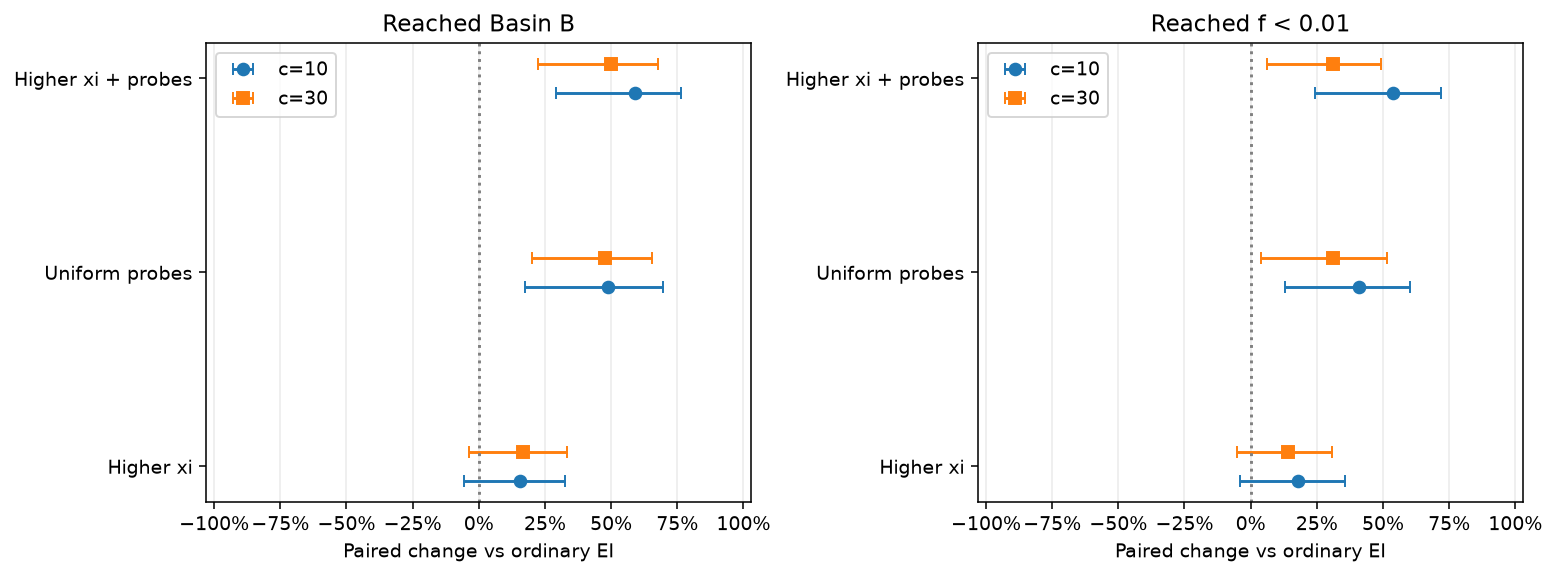

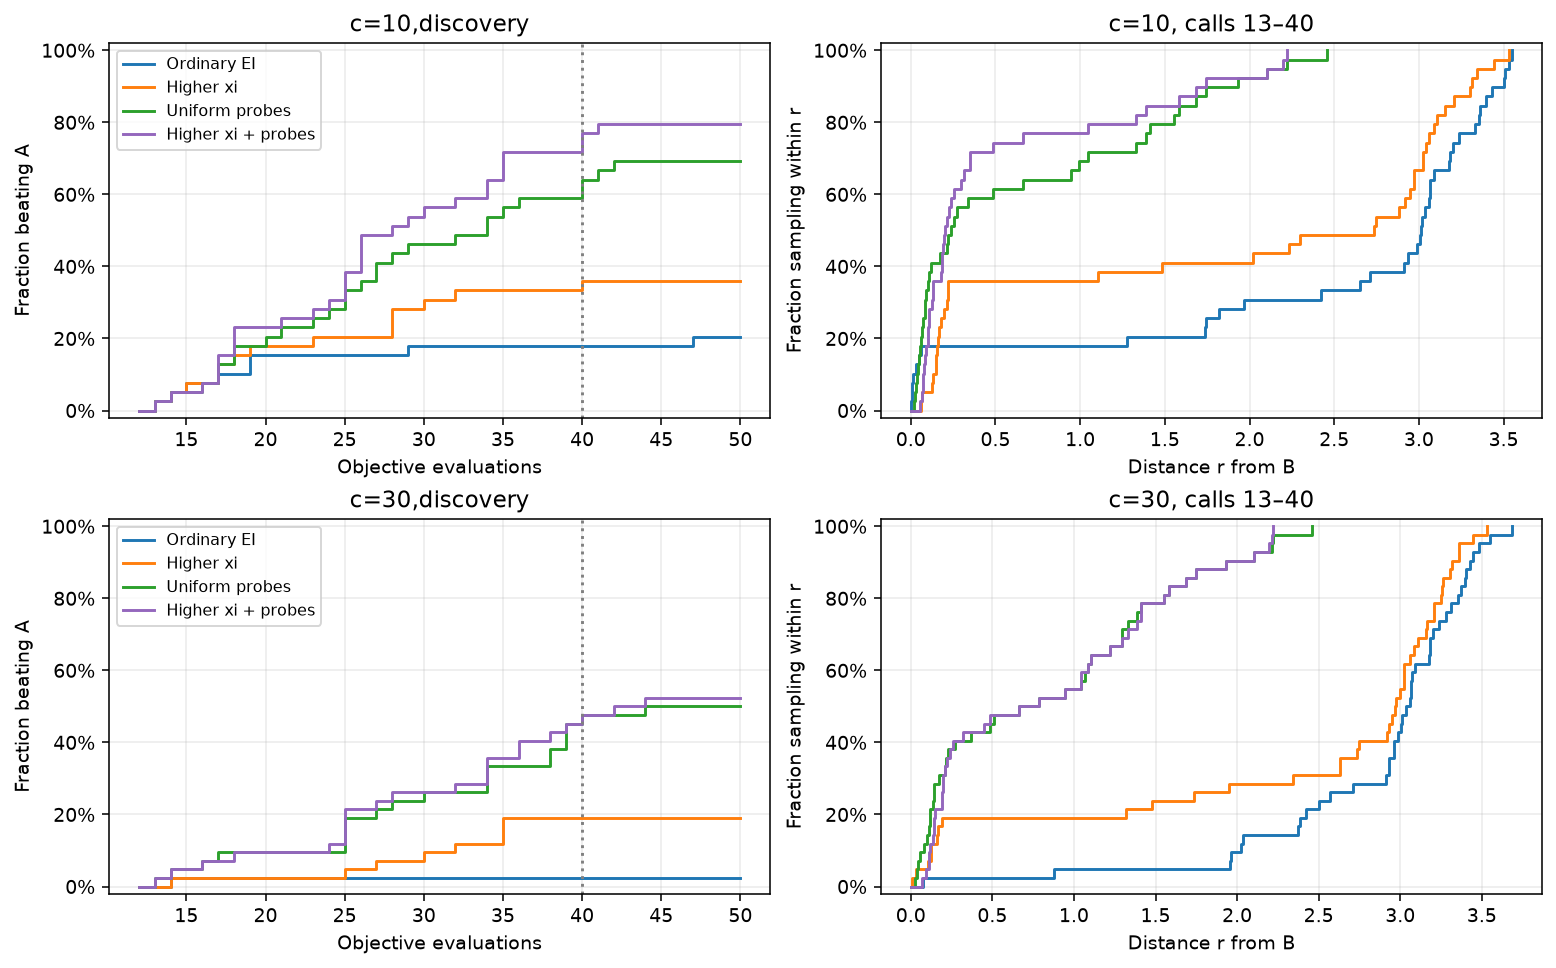

In [6]:
colors = dict(zip(arms, ["tab:blue", "tab:orange", "tab:green", "tab:purple"]))
markers = ["o", "s"]
treatments = list(arms)[1:]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, outcome, title in zip(axes, ["discovered", "precise"], ["Reached Basin B", "Reached f < 0.01"]):
    for i, c in enumerate(PENALTIES):
        block = effects.loc[(effects["c"] == c) & (effects["outcome"] == outcome)
                            & (effects["control"] == "Ordinary EI")].set_index("treatment").loc[treatments]
        positions = np.arange(len(treatments)) + (i - 0.5) * 0.15
        ax.errorbar(block["change"], positions,
                    xerr=[block["change"] - block["low"], block["high"] - block["change"]],
                    fmt=markers[i], capsize=3, label=f"c={c}")
    ax.axvline(0, color="0.5", linestyle=":")
    ax.set_yticks(range(len(treatments)), treatments)
    ax.set(title=title, xlabel="Paired change vs ordinary EI", xlim=(-1.03, 1.03))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", alpha=0.25)
    ax.legend()
fig.savefig(run_dir / "paired_outcomes.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 6.8), layout="constrained")
calls = np.arange(FORK, BUDGET + 1)
for c, (time_ax, distance_ax) in zip(PENALTIES, axes):
    group = trials[trials["c"] == c]
    for arm, subset in group.groupby("arm", sort=False):
        hits = subset["discovery_call"].fillna(np.inf).to_numpy()
        time_ax.step(calls, (hits[:, None] <= calls).mean(axis=0), where="post",
                     color=colors[arm], label=arm)
        distances = np.sort(subset["closest_b"].to_numpy())
        distance_ax.step(np.r_[0, distances], np.arange(len(distances) + 1) / len(distances),
                         where="post", color=colors[arm])
    time_ax.axvline(EXPLORE_END, color="0.5", linestyle=":")
    time_ax.set(title=f"c={c},discovery", xlabel="Objective evaluations", ylabel="Fraction beating A")
    distance_ax.set(title=f"c={c}, calls 13–40", xlabel="Distance r from B",
                    ylabel="Fraction sampling within r")
    for ax in (time_ax, distance_ax):
        ax.set_ylim(-0.02, 1.02)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(alpha=0.25)
    time_ax.legend(fontsize=8)
fig.savefig(run_dir / "discovery_and_coverage.png", dpi=150)
plt.show()

### Figure 1 interpretation
Both variants with probes have intervals above zero for both targets at both penalties. For probes alone, the discovery intervals are $[17.4,69.6]$ percentage points at $c=10$ and $[20.2,65.6]$ at $c=30$. The corresponding precision intervals are $[13.1,60.1]$ and $[3.7,51.7]$. Thus the gain remains visible at the stricter target, although the precision gain is smaller than the discovery gain.

Higher $\xi$ alone has positive estimates in all four comparisons, but its intervals include zero. The combined variant has the largest observed gains at $c=10$. Adding higher $\xi$ to probes gives $+10.3$ percentage points for discovery and $+12.8$ for precision relative to probes alone at $c=10$, with both intervals including zero. 

### Figure 2 interpretation

At $c=10$, both probe curves performed better during the intervention, and the combined variant finishes highest. At $c=30$, ordinary EI's curve is nearly flat, while the two probe curves perform similarly, finishing near 50%. Ordinary EI made no late discoveries among eight eligible runs in Experiment 1, whereas it recovered on eight of 39 eligible seeds here at $c=10$.

In the right panels, at distance $r$, the vertical axis gives the fraction of runs that evaluated at least one point within $r$ of B. Each run contributes its closest point, so a higher curve at the same radius means that more runs reached that vicinity.

The probe variants reached B's vicinity more often even when judged at the same physical radius. They also spent
less of the intervention near A. For probes alone, the mean fraction of calls within distance 1 of A fell from 73.4% to 36.0% at $c=10$ and from 85.1% to 43.5% at $c=30$. Higher $\xi$ alone reduced concentration near A
and increased the number of newly visited grid cells, but shifted the median closest distance to B only modestly.


## 6. Conclusion

**The experiment supports the main hypothesis for uniform probes.**
Replacing ten EI proposals with uniform probes moved evaluations away from A, brought more runs close to B, and increased discovery by roughly 48 percentage points at both penalties. The discovery gains also carried through to final precision. Probes alone increased precision from **7/39 to 23/39** at $c=10$ and from **1/42 to 14/42** at $c=30$. At $c=10$, its median best value improved from $0.0572$ at call 40 to $0.00243$ at call 50, after all variants had returned to ordinary EI. This illustrates how the final ten EI calls could build on progress made during the exploration window. 

The evidence for higher $\xi$ alone is less conclusive: using $\xi=0.5$ increased coverage and produced more successes than ordinary EI, but all four paired confidence intervals include zero. 

These results support insufficient global exploration as one contributor to the early misses in Experiment 1. Uniform probes replace selected EI proposals while retaining the GP and its full observation history. They are not optimiser restarts. In this experiment, the additional coverage helped more runs discover B and then refine their solutions.